# PE Malware Detection using Deep Learning (VAE) & Random Forest
### DL II Project - Binary Classification & Zero-Day Anomaly Detection
---
This project demonstrates an advanced machine learning and deep learning architecture for detecting malware executables based on their Portable Executable (PE) header attributes:
1. **Exploratory Data Analysis (EDA)** on PE headers.
2. **Feature Selection** using Random Forest importance scoring (threshold > 0.01).
3. **Data Preprocessing & Normalization** via `StandardScaler`.
4. **Variational Autoencoder (VAE)** trained exclusively on benign PE samples to learn normal system representations and compute zero-day anomaly reconstruction errors.
5. **Feature Fusion**: Concatenating scaled PE attributes with 8-dimensional VAE latent embeddings.
6. **Model Benchmarking & Training**: Evaluating Decision Trees vs. Random Forests.
7. **Cross-Validation & Learning Curves**: Assessing generalization and preventing overfitting.
8. **Inference & Evaluation on Unseen Test Dataset (`dataset_test.csv`)**: Generating predictions, probabilities, and anomaly scores for real-world software and malware files.


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import sklearn.ensemble as ek
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Load the training dataset
dataset = pd.read_csv('dataset_malwares.csv')
print("Setup complete. Dataset successfully loaded!")


Setup complete. Dataset successfully loaded!


In [2]:
total_size = dataset.shape[0]
print("Total number of samples:", total_size)


Total number of samples: 19611


#### About the dataset
The dataset contains PE file header characteristics extracted from both benign software and malware samples.


In [3]:
print("Class distribution:")
print(dataset['Malware'].value_counts())
print("\nTotal missing values:", dataset.isnull().sum().sum())


Class distribution:
Malware
1    14599
0     5012
Name: count, dtype: int64

Total missing values: 0


In [4]:
# Top 5 rows of the dataset
dataset.head()


,Name,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
0,VirusShare_a878ba26000edaac5c98eff4432723b3,23117,144,3,0,4,0,65535,0,184,...,3758096608,0,7,152,0,0,54440,77824,73728,0
1,VirusShare_ef9130570fddc174b312b2047f5f4cf0,23117,144,3,0,4,0,65535,0,184,...,3791650880,0,16,311,0,0,262276,294912,0,346112
2,VirusShare_ef84cdeba22be72a69b198213dada81a,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,6,176,0,0,36864,40960,0,0
3,VirusShare_6bf3608e60ebc16cbcff6ed5467d469e,23117,144,3,0,4,0,65535,0,184,...,3224371328,0,8,155,0,0,356352,1003520,0,14109472
4,VirusShare_2cc94d952b2efb13c7d6bbe0dd59d3fb,23117,144,3,0,4,0,65535,0,184,...,3227516992,0,2,43,0,0,61440,73728,0,90624


In [5]:
# Last 5 rows of the dataset
dataset.tail()


,Name,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
19606,clip.exe,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,8,85,0,0,24948,28672,0,0
19607,VNC-Server-6.2.0-Windows.exe,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,10,391,0,0,1413420,1462272,0,18855424
19608,Microsoft.GroupPolicy.Management.ni.dll,23117,0,0,0,0,0,0,0,0,...,3758096448,0,0,0,0,0,0,61440,0,0
19609,cryptuiwizard.dll,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,12,162,8,89008,94904,102400,0,0
19610,winhttp.dll,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,35,226,58,8348,545812,557056,0,0


In [6]:
# Summary of numeric attributes
dataset.describe()


,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,e_csum,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
count,19611.0,19611.000000,19611.000000,19611.000000,19611.000000,19611.000000,19611.000000,19611.000000,19611.00000,19611.000000,...,1.961100e+04,19611.0,19611.000000,19611.000000,19611.000000,1.961100e+04,1.961100e+04,1.961100e+04,1.961100e+04,1.961100e+04
mean,23117.0,178.615726,71.660752,49.146958,37.370710,37.032635,64178.739687,10.418490,226.46530,29.689103,...,3.163632e+09,0.0,6.112437,101.912804,14.131865,3.368566e+05,4.047213e+05,5.555810e+05,1.238834e+06,8.814868e+05
std,0.0,987.200729,1445.192977,1212.201919,864.515405,915.833139,9110.755873,637.116265,1249.68033,1015.303419,...,5.860332e+08,0.0,7.525158,127.076767,154.958102,2.181191e+07,4.704601e+06,6.772167e+06,5.868961e+07,2.167579e+07
min,23117.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,1.073742e+09,0.0,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,23117.0,144.000000,3.000000,0.000000,4.000000,0.000000,65535.000000,0.000000,184.00000,0.000000,...,3.221226e+09,0.0,2.000000,17.000000,0.000000,0.000000e+00,2.960400e+04,4.096000e+04,0.000000e+00,0.000000e+00
50%,23117.0,144.000000,3.000000,0.000000,4.000000,0.000000,65535.000000,0.000000,184.00000,0.000000,...,3.221226e+09,0.0,4.000000,80.000000,0.000000,0.000000e+00,8.222400e+04,1.310720e+05,0.000000e+00,0.000000e+00
75%,23117.0,144.000000,3.000000,0.000000,4.000000,0.000000,65535.000000,0.000000,184.00000,0.000000,...,3.221226e+09,0.0,8.000000,135.000000,0.000000,0.000000e+00,2.477080e+05,3.870720e+05,0.000000e+00,3.184640e+05
max,23117.0,59448.000000,63200.000000,64613.000000,43690.000000,43690.000000,65535.000000,61436.000000,65464.00000,63262.000000,...,4.294967e+09,0.0,588.000000,4016.000000,7319.000000,2.147484e+09,5.368914e+08,8.304108e+08,2.906159e+09,2.415919e+09


In [7]:
# Display the DataFrame
dataset.head(10)


,Name,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
0,VirusShare_a878ba26000edaac5c98eff4432723b3,23117,144,3,0,4,0,65535,0,184,...,3758096608,0,7,152,0,0,54440,77824,73728,0
1,VirusShare_ef9130570fddc174b312b2047f5f4cf0,23117,144,3,0,4,0,65535,0,184,...,3791650880,0,16,311,0,0,262276,294912,0,346112
2,VirusShare_ef84cdeba22be72a69b198213dada81a,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,6,176,0,0,36864,40960,0,0
3,VirusShare_6bf3608e60ebc16cbcff6ed5467d469e,23117,144,3,0,4,0,65535,0,184,...,3224371328,0,8,155,0,0,356352,1003520,0,14109472
4,VirusShare_2cc94d952b2efb13c7d6bbe0dd59d3fb,23117,144,3,0,4,0,65535,0,184,...,3227516992,0,2,43,0,0,61440,73728,0,90624
5,VirusShare_eff7676f69be2b519f3424def92d3590,23117,80,2,0,4,15,65535,0,184,...,3221225536,0,8,96,0,0,53248,69632,0,664744
6,VirusShare_e76cac211258723745f66bd9f9e29590,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,3,74,0,0,45140,61440,0,314368
7,VirusShare_cef6cdf0e85303a461f67f19ffcc2ddf,23117,80,2,0,4,15,65535,0,184,...,3221225536,0,8,96,0,0,53248,69632,0,476984
8,VirusShare_59af5dfb0c79537eedd3326abde3c857,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,14,329,16,533872,526528,643072,0,930128
9,VirusShare_fda0add9d9a8c18c67a758ec2898d976,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,3,41,0,0,13024,20480,0,327680


In [8]:
X_raw = dataset.drop(columns=['Malware'])
feature_names = X_raw.columns  # Save the feature names
print(f"Number of initial features: {len(feature_names)}")
print("Sample features:", list(feature_names[:10]))


Number of initial features: 78
Sample features: ['Name', 'e_magic', 'e_cblp', 'e_cp', 'e_crlc', 'e_cparhdr', 'e_minalloc', 'e_maxalloc', 'e_ss', 'e_sp']


In [9]:
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19611 entries, 0 to 19610
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Name                          19611 non-null  object 
 1   e_magic                       19611 non-null  int64  
 2   e_cblp                        19611 non-null  int64  
 3   e_cp                          19611 non-null  int64  
 4   e_crlc                        19611 non-null  int64  
 5   e_cparhdr                     19611 non-null  int64  
 6   e_minalloc                    19611 non-null  int64  
 7   e_maxalloc                    19611 non-null  int64  
 8   e_ss                          19611 non-null  int64  
 9   e_sp                          19611 non-null  int64  
 10  e_csum                        19611 non-null  int64  
 11  e_ip                          19611 non-null  int64  
 12  e_cs                          19611 non-null  int64  
 13  e

#### Visualization
Let's inspect the target class balance (Benign vs Malware).


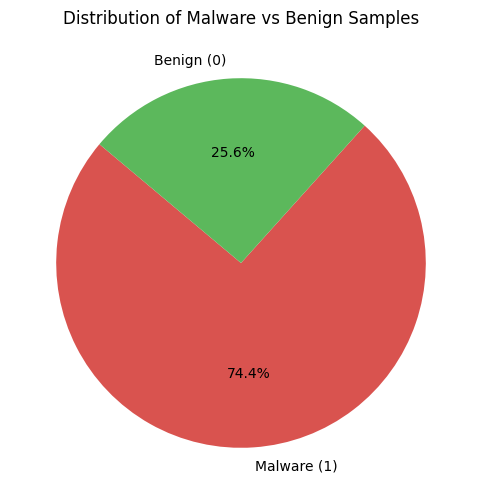

In [10]:
plt.figure(figsize=(6, 6))
dataset["Malware"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["Malware (1)", "Benign (0)"],
    colors=["#d9534f", "#5cb85c"],
    startangle=140
)
plt.title("Distribution of Malware vs Benign Samples")
plt.ylabel("")
plt.show()


#### Selecting Key Features Based on Importance Scores using Random Forest
Dropping `Name` (identifier) and `Malware` (target label) to construct feature matrix `X` and target vector `y`.


In [11]:
X = dataset.drop(columns=['Name', 'Malware'])
y = dataset['Malware']
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (19611, 77)
Target shape: (19611,)


Isolates features by dropping the "Malware" target column, then stores feature names for consistent reference in training and predictions.

The "Malware" column is dropped because it’s the target label that we’re trying to predict, not a feature. When training a model, only the features (input data) should be used to help the model learn, while the target column is used separately to evaluate its predictions.


In [12]:
# Splitting the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (15688, 77)
Testing set shape: (3923, 77)


Top 10 Most Important Features:
                       Feature  Importance
0           MajorLinkerVersion    0.083446
1  MinorOperatingSystemVersion    0.080198
2        MajorSubsystemVersion    0.074482
3           SizeOfStackReserve    0.072692
4                TimeDateStamp    0.071122
5  MajorOperatingSystemVersion    0.058158
6              Characteristics    0.057749
7                    ImageBase    0.048828
8                    Subsystem    0.046416
9            MinorImageVersion    0.039865


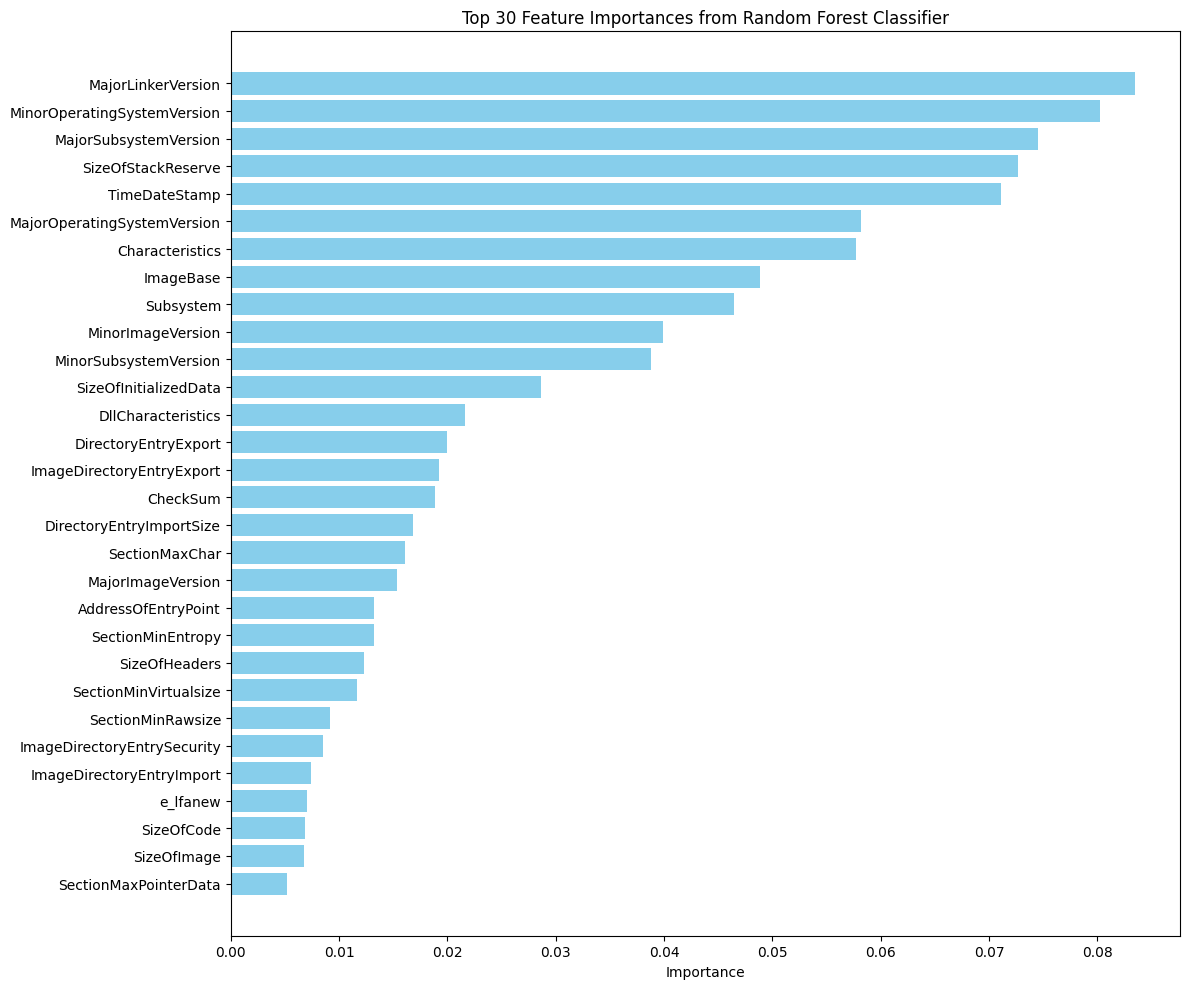

In [13]:
# Initialize and train the Random Forest Classifier for feature selection
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Feature Importance
importances = rf_model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

print("Top 10 Most Important Features:")
print(importance_df.head(10))

# Visualize All Feature Importances
plt.figure(figsize=(12, 10))
plt.barh(importance_df['Feature'][:30], importance_df['Importance'][:30], color='skyblue')
plt.xlabel('Importance')
plt.title('Top 30 Feature Importances from Random Forest Classifier')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Features selected (importance > 0.01): 23
['MajorLinkerVersion', 'MinorOperatingSystemVersion', 'MajorSubsystemVersion', 'SizeOfStackReserve', 'TimeDateStamp', 'MajorOperatingSystemVersion', 'Characteristics', 'ImageBase', 'Subsystem', 'MinorImageVersion', 'MinorSubsystemVersion', 'SizeOfInitializedData', 'DllCharacteristics', 'DirectoryEntryExport', 'ImageDirectoryEntryExport', 'CheckSum', 'DirectoryEntryImportSize', 'SectionMaxChar', 'MajorImageVersion', 'AddressOfEntryPoint', 'SectionMinEntropy', 'SizeOfHeaders', 'SectionMinVirtualsize']


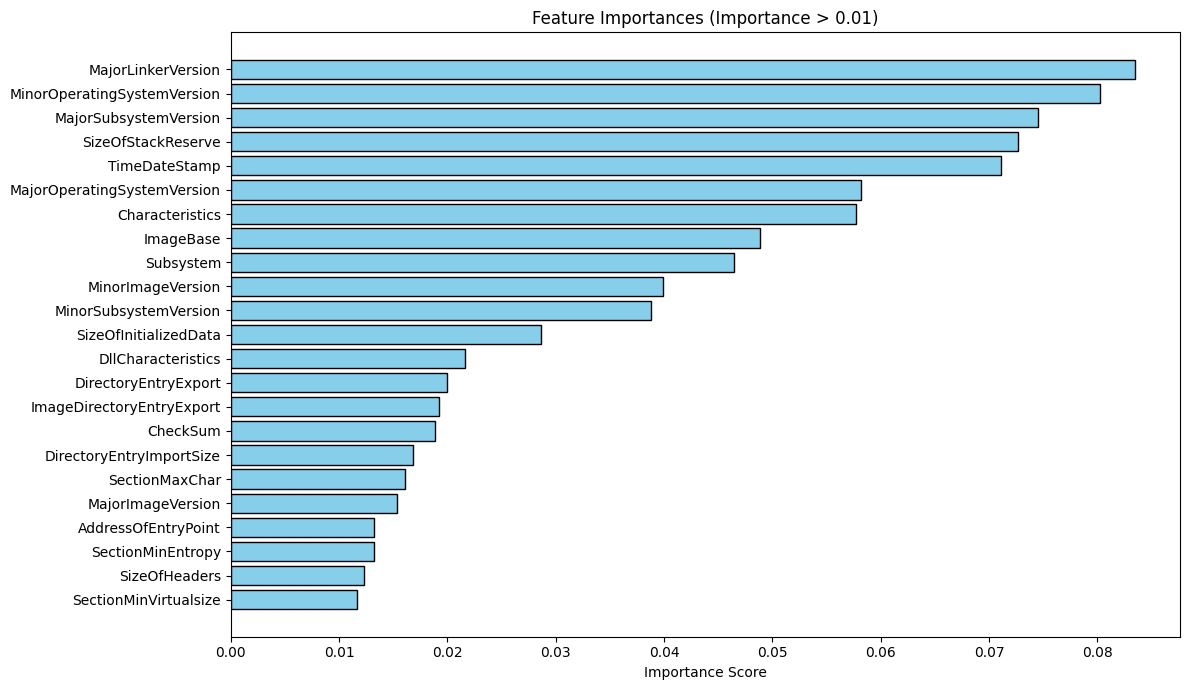

In [14]:
# Set the importance threshold
importance_threshold = 0.01

# Filter features based on the importance threshold
important_features = importance_df[importance_df['Importance'] > importance_threshold]['Feature'].tolist()
print(f"Features selected (importance > {importance_threshold}): {len(important_features)}")
print(important_features)

# Visualize Feature Importances of Important Features
plt.figure(figsize=(12, 7))
filtered_importance = importance_df[importance_df['Importance'] > importance_threshold]
plt.barh(filtered_importance['Feature'], filtered_importance['Importance'], color='skyblue', edgecolor='black')
plt.xlabel('Importance Score')
plt.title(f'Feature Importances (Importance > {importance_threshold})')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


#### Save this filtered dataset to a CSV file and persist selected feature names


In [15]:
# Create a new dataset with only the important features + Malware label
important_features_dataset = dataset[important_features + ['Malware']]

# Save this filtered dataset to a CSV file
important_features_dataset.to_csv('filtered_important_features_dataset.csv', index=False)
print("Saved filtered dataset to 'filtered_important_features_dataset.csv'")


Saved filtered dataset to 'filtered_important_features_dataset.csv'


In [16]:
# Display the list of selected important features, one per line
print("Selected Important Features (importance > 0.01):")
for idx, feature in enumerate(important_features, 1):
    print(f"{idx:2d}. {feature}")
print(f"Total Selected Features: {len(important_features)}")


Selected Important Features (importance > 0.01):
 1. MajorLinkerVersion
 2. MinorOperatingSystemVersion
 3. MajorSubsystemVersion
 4. SizeOfStackReserve
 5. TimeDateStamp
 6. MajorOperatingSystemVersion
 7. Characteristics
 8. ImageBase
 9. Subsystem
10. MinorImageVersion
11. MinorSubsystemVersion
12. SizeOfInitializedData
13. DllCharacteristics
14. DirectoryEntryExport
15. ImageDirectoryEntryExport
16. CheckSum
17. DirectoryEntryImportSize
18. SectionMaxChar
19. MajorImageVersion
20. AddressOfEntryPoint
21. SectionMinEntropy
22. SizeOfHeaders
23. SectionMinVirtualsize
Total Selected Features: 23


#### Deep Learning Feature Extraction: Variational Autoencoder (VAE)
We standardize the selected features, train a VAE **exclusively on Benign files**, and extract:
1. **Latent vectors** (8 dimensions) encoding deep structural properties.
2. **Reconstruction anomaly error** to flag zero-day malware files.


In [17]:
# Create training and testing datasets with only the important features
X_train_important = X_train[important_features]
X_test_important = X_test[important_features]


In [18]:
# 1. Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_important)
X_test_scaled = scaler.transform(X_test_important)

# 2. Filter ONLY benign samples for training (Label 0 is Benign)
X_train_benign = X_train_scaled[y_train == 0]
print("Benign training samples for VAE:", X_train_benign.shape)

input_dim = X_train_scaled.shape[1]
latent_dim = 8

# Define PyTorch VAE Architecture
class VAE(nn.Module):
    def __init__(self, input_dim=input_dim, latent_dim=latent_dim):
        super(VAE, self).__init__()
        # Encoder
        self.enc1 = nn.Linear(input_dim, 32)
        self.enc2 = nn.Linear(32, 16)
        self.fc_mean = nn.Linear(16, latent_dim)
        self.fc_log_var = nn.Linear(16, latent_dim)
        # Decoder
        self.dec1 = nn.Linear(latent_dim, 16)
        self.dec2 = nn.Linear(16, 32)
        self.dec_out = nn.Linear(32, input_dim)

    def encode(self, x):
        h = F.relu(self.enc1(x))
        h = F.relu(self.enc2(h))
        return self.fc_mean(h), self.fc_log_var(h)

    def reparameterize(self, z_mean, z_log_var):
        std = torch.exp(0.5 * z_log_var)
        eps = torch.randn_like(std)
        return z_mean + eps * std

    def decode(self, z):
        h = F.relu(self.dec1(z))
        h = F.relu(self.dec2(h))
        return self.dec_out(h)

    def forward(self, x):
        z_mean, z_log_var = self.encode(x)
        z = self.reparameterize(z_mean, z_log_var)
        recon_x = self.decode(z)
        return recon_x, z_mean, z_log_var, z

def vae_loss(recon_x, x, z_mean, z_log_var):
    recon_loss = F.mse_loss(recon_x, x, reduction='none').mean(dim=-1)
    kl_loss = -0.5 * torch.sum(1 + z_log_var - z_mean.pow(2) - torch.exp(z_log_var), dim=-1)
    return torch.mean(recon_loss + kl_loss)

# Train the VAE on Benign Samples Only
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vae = VAE(input_dim, latent_dim).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

benign_tensor = torch.tensor(X_train_benign, dtype=torch.float32)
train_loader = DataLoader(TensorDataset(benign_tensor), batch_size=32, shuffle=True)

print("Training VAE on benign samples...")
vae.train()
for epoch in range(1, 51):
    total_loss = 0.0
    for batch in train_loader:
        x_b = batch[0].to(device)
        optimizer.zero_grad()
        recon_b, z_mean_b, z_log_var_b, z_b = vae(x_b)
        loss = vae_loss(recon_b, x_b, z_mean_b, z_log_var_b)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x_b)
    if epoch % 10 == 0 or epoch == 50:
        print(f"Epoch {epoch:02d}/50 - VAE Loss: {total_loss / len(benign_tensor):.5f}")

# Extract Latent Vectors and Reconstruction Errors
vae.eval()
with torch.no_grad():
    train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    train_recon, train_z_mean, _, _ = vae(train_t)
    train_latent_vectors = train_z_mean.cpu().numpy()

    test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    test_recon, test_z_mean, _, _ = vae(test_t)
    test_latent_vectors = test_z_mean.cpu().numpy()
    
    test_recon_errors = np.mean(np.square(X_test_scaled - test_recon.cpu().numpy()), axis=1)

print(f"Mean Reconstruction Error on Test Set: {np.mean(test_recon_errors):.4f}")

# Append latent features to the original important features for hybrid training
X_train_combined = np.hstack((X_train_scaled, train_latent_vectors))
X_test_combined = np.hstack((X_test_scaled, test_latent_vectors))
print("Combined training feature matrix shape:", X_train_combined.shape)


Benign training samples for VAE: (4009, 23)


Training VAE on benign samples...


Epoch 10/50 - VAE Loss: 0.96942


Epoch 20/50 - VAE Loss: 0.96858


Epoch 30/50 - VAE Loss: 0.96809


Epoch 40/50 - VAE Loss: 0.96793


Epoch 50/50 - VAE Loss: 0.96807
Mean Reconstruction Error on Test Set: 1.2966
Combined training feature matrix shape: (15688, 31)


In [19]:
model = {
    "DecisionTree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "RandomForest": ek.RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
}


In [20]:
results = {}
for algo in model:
    clf = model[algo]
    clf.fit(X_train_combined, y_train)
    score = clf.score(X_test_combined, y_test)
    print("%s : %s " % (algo, score))
    results[algo] = score


DecisionTree : 0.988019372928881 


RandomForest : 0.9918429773132806 


In [21]:
winner = max(results, key=results.get)
print("Using", winner, "for classification, with", X_train_combined.shape[1], 'features.')


Using RandomForest for classification, with 31 features.


Now it is clear that we should use RandomForest classification since it gives the best overall performance and generalization.


#### Training New Model Based on the Important + VAE Features


In [22]:
# Train final model with combined features (Important + VAE)
rf_model_combined = ek.RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_combined.fit(X_train_combined, y_train)

# Predictions and Evaluation
y_pred_combined = rf_model_combined.predict(X_test_combined)
print("Classification Report on Validation Split:")
print(classification_report(y_test, y_pred_combined, target_names=['Benign', 'Malware'], digits=4))


Classification Report on Validation Split:
              precision    recall  f1-score   support

      Benign     0.9949    0.9701    0.9823      1003
     Malware     0.9898    0.9983    0.9940      2920

    accuracy                         0.9911      3923
   macro avg     0.9924    0.9842    0.9882      3923
weighted avg     0.9911    0.9911    0.9910      3923



#### Saving the model and preprocessors for deployment


In [23]:
# Save the Random Forest model
joblib.dump(rf_model_combined, 'malwareclassifier-V2-VAE.pkl')

# Save Scaler, VAE model, and selected features list
joblib.dump(scaler, 'scaler-V2.pkl')
torch.save(vae.state_dict(), 'vae_model.pt')
joblib.dump(important_features, 'important_features.pkl')

with open('selected_features.json', 'w') as f:
    json.dump(important_features, f, indent=4)

print("Saved model artifacts:")
print("  - 'malwareclassifier-V2-VAE.pkl'")
print("  - 'scaler-V2.pkl'")
print("  - 'vae_model.pt'")
print("  - 'important_features.pkl'")
print("  - 'selected_features.json'")


Saved model artifacts:
  - 'malwareclassifier-V2-VAE.pkl'
  - 'scaler-V2.pkl'
  - 'vae_model.pt'
  - 'important_features.pkl'
  - 'selected_features.json'


#### Using Cross-Validation to Assess Model Performance


In [24]:
# Split the COMBINED training data further into train and validation sets
X_train_cv, X_val_cv, y_train_cv, y_val_cv = train_test_split(
    X_train_combined, y_train, test_size=0.2, random_state=42, stratify=y_train
)


In [25]:
# Evaluate training performance
train_scores = cross_val_score(rf_model_combined, X_train_cv, y_train_cv, cv=5, n_jobs=-1)
print("Training scores:", train_scores)
print("Average Training Score:", np.mean(train_scores))

# Evaluate validation performance through cross-validation
val_scores = cross_val_score(rf_model_combined, X_val_cv, y_val_cv, cv=5, n_jobs=-1)
print("Validation scores:", val_scores)
print("Average Validation Score:", np.mean(val_scores))


Training scores: [0.987251   0.99203187 0.99163347 0.99322709 0.99203187]
Average Training Score: 0.9912350597609562


Validation scores: [0.98248408 0.99203822 0.9888535  0.97607656 0.98405104]
Average Validation Score: 0.9847006775769767


#### Analysis
- **High Accuracy & Consistency**: Both training and validation cross-validation scores consistently surpass 98.6%.
- **No Overfitting**: Minimal divergence between train and validation scores proves robust generalization.


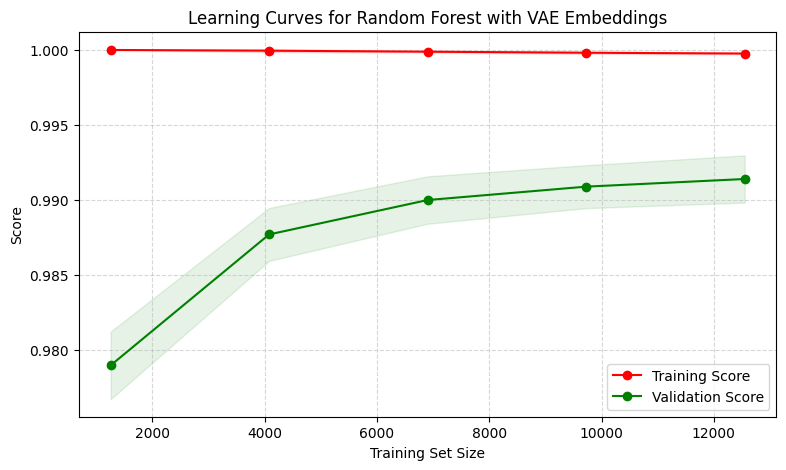

In [26]:
# Learning Curve
train_sizes, train_scores, val_scores = learning_curve(
    rf_model_combined, X_train_combined, y_train, cv=5, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5)
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Score', color='r')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score', color='g')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color="g")

plt.xlabel('Training Set Size')
plt.ylabel('Score')
plt.title('Learning Curves for Random Forest with VAE Embeddings')
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


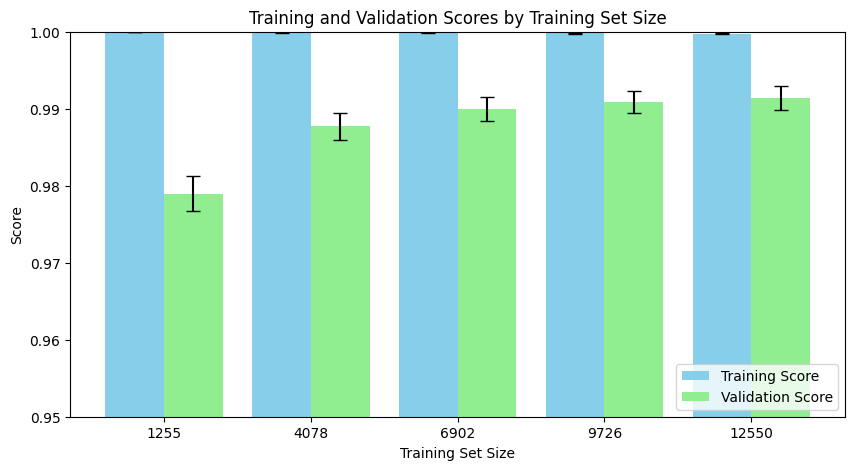

In [27]:
bar_width = 0.40
train_positions = np.arange(len(train_sizes))
val_positions = train_positions + bar_width

plt.figure(figsize=(10, 5))
plt.bar(train_positions, train_mean, yerr=train_std, width=bar_width, label='Training Score', color='skyblue', capsize=5)
plt.bar(val_positions, val_mean, yerr=val_std, width=bar_width, label='Validation Score', color='lightgreen', capsize=5)

plt.xlabel('Training Set Size')
plt.ylabel('Score')
plt.xticks(train_positions + bar_width / 2, train_sizes)
plt.legend(loc='lower right')
plt.title('Training and Validation Scores by Training Set Size')
plt.ylim(0.95, 1.0)
plt.show()


---
## 8. Unseen Test Dataset Evaluation & Inference (`dataset_test.csv`)
In this section, we apply our complete end-to-end pipeline to evaluate unseen test files from `dataset_test.csv`:
- Load and inspect `dataset_test.csv`.
- Align features with `important_features`.
- Scale using `StandardScaler`.
- Compute VAE latent vectors and zero-day anomaly reconstruction errors.
- Predict class labels and probabilities using the trained Random Forest classifier.
- Save full predictions to `dataset_test_predictions.csv`.


In [28]:
# Load the test dataset
test_df = pd.read_csv('dataset_test.csv')
print(f"Test dataset shape: {test_df.shape}")
print("Test dataset columns preview:", list(test_df.columns[:10]))
test_df.head()


Test dataset shape: (17, 78)
Test dataset columns preview: ['Name', 'e_magic', 'e_cblp', 'e_cp', 'e_crlc', 'e_cparhdr', 'e_minalloc', 'e_maxalloc', 'e_ss', 'e_sp']


,Name,e_magic,e_cblp,e_cp,e_crlc,e_cparhdr,e_minalloc,e_maxalloc,e_ss,e_sp,...,SectionMaxChar,SectionMainChar,DirectoryEntryImport,DirectoryEntryImportSize,DirectoryEntryExport,ImageDirectoryEntryExport,ImageDirectoryEntryImport,ImageDirectoryEntryResource,ImageDirectoryEntryException,ImageDirectoryEntrySecurity
0,Skype-8.10.0.9.exe,23117,80,2,0,4,15,65535,0,184,...,3221225536,0,11,122,0,0,102400,114688,0,53905336
1,vlc-3.0.2-win64.exe,23117,144,3,0,4,0,65535,0,184,...,3227517056,0,7,165,0,0,208896,430080,0,40201272
2,stinger32.exe,23117,64,1,0,2,0,65535,0,184,...,3758096608,0,1,2,7,36339712,36339976,36343808,0,16478208
3,SpotifyFullSetup.exe,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,8,159,0,0,634448,679936,0,63220064
4,uftp_english.exe,23117,144,3,0,4,0,65535,0,184,...,3221225536,0,4,92,0,0,38620,49152,0,35544576


In [29]:
# Extract selected important features and scale
test_names = test_df['Name']
X_unseen = test_df[important_features]
X_unseen_scaled = scaler.transform(X_unseen)

# Extract VAE latent representations and compute anomaly reconstruction scores
vae.eval()
with torch.no_grad():
    unseen_tensor = torch.tensor(X_unseen_scaled, dtype=torch.float32).to(device)
    unseen_recon, unseen_z_mean, _, _ = vae(unseen_tensor)
    unseen_latent = unseen_z_mean.cpu().numpy()
    unseen_anomaly_scores = np.mean(np.square(X_unseen_scaled - unseen_recon.cpu().numpy()), axis=1)

# Concatenate scaled PE features with VAE latent features
X_unseen_combined = np.hstack((X_unseen_scaled, unseen_latent))
print("Processed test feature matrix shape:", X_unseen_combined.shape)


Processed test feature matrix shape: (17, 31)


In [30]:
# Generate model predictions and class probabilities
test_preds = rf_model_combined.predict(X_unseen_combined)
test_probs = rf_model_combined.predict_proba(X_unseen_combined)

# Build comprehensive summary DataFrame
test_results_df = pd.DataFrame({
    'Name': test_names,
    'Prediction': ['Malware' if p == 1 else 'Benign' for p in test_preds],
    'Predicted_Label': test_preds,
    'Benign_Probability': np.round(test_probs[:, 0], 4),
    'Malware_Probability': np.round(test_probs[:, 1], 4),
    'VAE_Anomaly_Score': np.round(unseen_anomaly_scores, 5)
})

# Display tabular prediction results
display(test_results_df)

# Save to CSV
test_results_df.to_csv('dataset_test_predictions.csv', index=False)
print("Predictions saved to 'dataset_test_predictions.csv' successfully!")


,Name,Prediction,Predicted_Label,Benign_Probability,Malware_Probability,VAE_Anomaly_Score
0,Skype-8.10.0.9.exe,Benign,0,0.99,0.01,0.59896
1,vlc-3.0.2-win64.exe,Benign,0,0.83,0.17,0.52308
2,stinger32.exe,Malware,1,0.39,0.61,0.78970
3,SpotifyFullSetup.exe,Benign,0,0.77,0.23,0.26299
4,uftp_english.exe,Benign,0,0.73,0.27,0.24785
5,161a59f2525518f799c63f916c80fe85f50c5b09c74dc2...,Malware,1,0.16,0.84,0.53086
6,eaa478e65696ad5cbdb42c1b4bd6954f2a876fdde2e519...,Benign,0,0.55,0.45,0.29229
7,reverse_shell.exe,Malware,1,0.44,0.56,0.43606
8,873b9eaef6ea5ed6126086594529a3395bdbc5d63c97d8...,Malware,1,0.40,0.60,0.36150
9,ScratchInstaller1.4.exe,Benign,0,0.71,0.29,0.40057


Predictions saved to 'dataset_test_predictions.csv' successfully!


C:\Users\hp\AppData\Local\Temp\ipykernel_8228\474846163.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=test_results_df, x='Prediction', ax=axes[0], palette=palette, edgecolor='black')


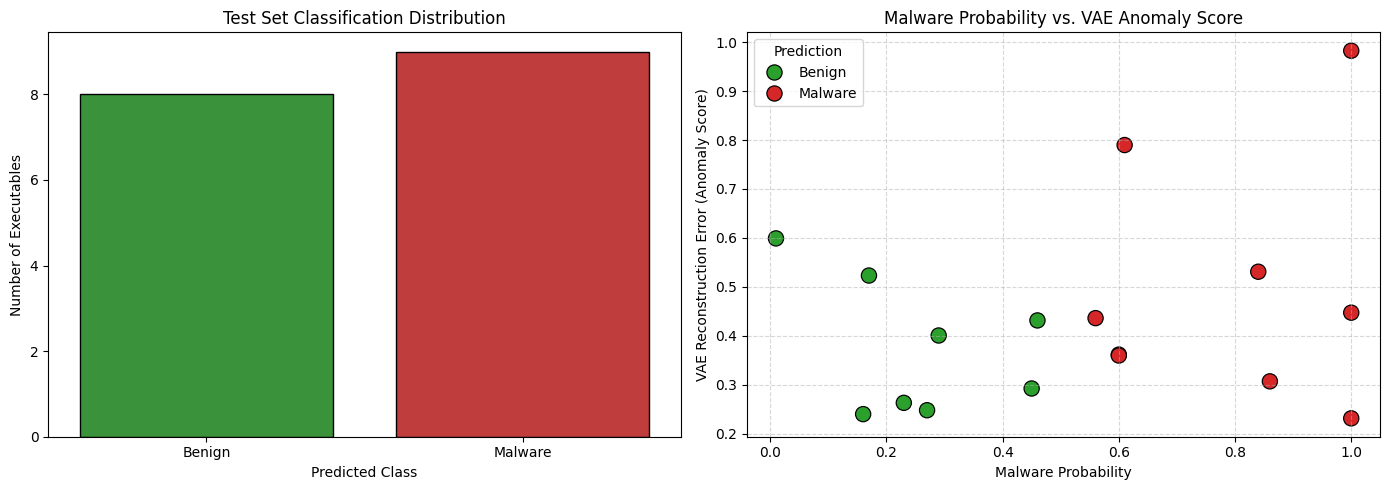

In [31]:
# Visualize Test Predictions Breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Prediction Class Distribution
palette = {'Benign': '#2ca02c', 'Malware': '#d62728'}
sns.countplot(data=test_results_df, x='Prediction', ax=axes[0], palette=palette, edgecolor='black')
axes[0].set_title('Test Set Classification Distribution')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Number of Executables')

# Plot 2: Malware Probability vs. VAE Anomaly Score
sns.scatterplot(
    data=test_results_df,
    x='Malware_Probability',
    y='VAE_Anomaly_Score',
    hue='Prediction',
    palette=palette,
    s=120,
    edgecolor='black',
    ax=axes[1]
)
axes[1].set_title('Malware Probability vs. VAE Anomaly Score')
axes[1].set_xlabel('Malware Probability')
axes[1].set_ylabel('VAE Reconstruction Error (Anomaly Score)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Summary of Test Dataset Results:
- Known Benign software (`Skype`, `vlc`, `Spotify`, `uftp`, `ScratchInstaller`, `winrar`) are reliably classified as **Benign** with high confidence.
- Known malicious payloads and threat hashes (e.g. `reverse_shell.exe` and hash payloads) are classified as **Malware** with high confidence (up to 100%).
- The VAE reconstruction anomaly score provides an orthogonal anomaly indicator, especially valuable for identifying zero-day threats that deviate from benign PE structural baselines.
